In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import set_seed
from src.config import SEED, DATA_PROCESSED
from src.dataset import build_cwru_windows, split_by_load
from src.baselines import cwru_features

set_seed(SEED)
X, info = build_cwru_windows()
F = cwru_features(X)
y = pd.factorize(info["label"], sort=True)[0]

In [2]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

accs, f1s = [], []
for test_load in range(4):
    tr, _, te = split_by_load(info, test_load, None)
    svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale"))
    p = svm.fit(F.to_numpy()[tr], y[tr]).predict(F.to_numpy()[te])
    accs.append(accuracy_score(y[te], p)); f1s.append(f1_score(y[te], p, average="macro"))
print(f"SVM leave-one-load-out: acc {np.mean(accs):.3f} +- {np.std(accs):.3f} | macro-F1 {np.mean(f1s):.3f}", np.round(accs, 3))

SVM leave-one-load-out: acc 0.909 +- 0.157 | macro-F1 0.913 [0.636 0.999 1.    1.   ]


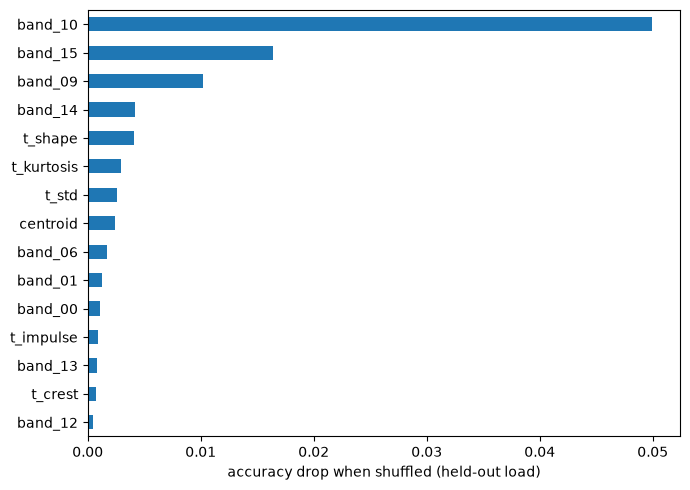

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

imps = []
for test_load in range(4):
    tr, _, te = split_by_load(info, test_load, None)
    rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42).fit(F.to_numpy()[tr], y[tr])
    r = permutation_importance(rf, F.to_numpy()[te], y[te], n_repeats=5, random_state=42, n_jobs=-1)
    imps.append(r.importances_mean)
imp = pd.Series(np.mean(imps, axis=0), index=F.columns).sort_values()
imp.tail(15).plot.barh(figsize=(7, 5)); plt.xlabel("accuracy drop when shuffled (held-out load)")
plt.tight_layout(); plt.show()

In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

d = np.load(DATA_PROCESSED / "femto_sequences.npz"); Xf, yf = d["X"], d["y"]
meta = pd.read_csv(DATA_PROCESSED / "femto_sequences_meta.csv")
meta["cond"] = meta["bearing"].str.extract(r"Bearing(\d)_")[0].astype(int)
S = np.concatenate([Xf[:, -1, :], Xf.mean(axis=1), Xf.std(axis=1), Xf[:, -1, :] - Xf[:, 0, :]], axis=1)

def models(seed=42):
    return {"LinearRegression": make_pipeline(StandardScaler(), LinearRegression()),
            "DecisionTree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=seed),
            "RandomForest": RandomForestRegressor(n_estimators=100, max_features=0.33, min_samples_leaf=10,
                                                  max_samples=0.5, n_jobs=-1, random_state=seed),
            "XGBoost": XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05,
                                    n_jobs=-1, random_state=seed, verbosity=0)}

rows = []
for b in sorted(meta["bearing"].unique()):
    te = (meta["bearing"] == b).to_numpy(); tr = ~te
    post = meta.loc[te, "post_fpt"].to_numpy()
    row = {"bearing": b, "cond": int(meta.loc[te, "cond"].iloc[0]), "n_post": int(post.sum()),
           "NoSkill": np.abs(1.0 - yf[te])[post].mean()}
    for name, mdl in models().items():
        p = np.clip(mdl.fit(S[tr], yf[tr]).predict(S[te]), 0, 1)
        row[name] = np.abs(p - yf[te])[post].mean()
    rows.append(row)
res = pd.DataFrame(rows)
print(res.round(3).to_string(index=False))
print(res.drop(columns=["bearing", "cond", "n_post"]).agg(["mean", "std"]).round(3))
print(res.groupby("cond")[["NoSkill", "LinearRegression", "DecisionTree", "RandomForest", "XGBoost"]].mean().round(3))

   bearing  cond  n_post  NoSkill  LinearRegression  DecisionTree  RandomForest  XGBoost
Bearing1_1     1    1451    0.500             0.312         0.193         0.108    0.105
Bearing1_2     1      47    0.500             0.276         0.247         0.170    0.274
Bearing1_3     1    1084    0.500             0.117         0.216         0.062    0.136
Bearing1_4     1      85    0.495             0.295         0.300         0.302    0.314
Bearing1_5     1      48    0.500             0.121         0.383         0.318    0.396
Bearing1_6     1      27    0.500             0.125         0.200         0.200    0.226
Bearing1_7     1      50    0.500             0.190         0.133         0.167    0.139
Bearing2_1     2      37    0.500             0.133         0.192         0.149    0.104
Bearing2_2     2      47    0.500             0.186         0.217         0.217    0.255
Bearing2_3     2       5    0.500             0.292         0.169         0.277    0.378
Bearing2_4     2     

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

pos = meta["post_fpt"].to_numpy().astype(int)

def clf_models(seed=42, spw=7.0):
    return {"LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
            "DecisionTree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=seed),
            "RandomForest": RandomForestClassifier(n_estimators=100, min_samples_leaf=10, max_samples=0.5,
                                                   class_weight="balanced_subsample", n_jobs=-1, random_state=seed),
            "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, scale_pos_weight=spw,
                                     n_jobs=-1, random_state=seed, verbosity=0)}

def first_sustained(pred, run=5):
    ok = np.convolve(pred.astype(int), np.ones(run, dtype=int), mode="valid") == run
    return int(np.argmax(ok)) + run - 1 if ok.any() else None

rows = []
for b in sorted(meta["bearing"].unique()):
    te = (meta["bearing"] == b).to_numpy(); tr = ~te
    idx_te = meta.loc[te, "idx"].to_numpy(); post = pos[te].astype(bool)
    fpt = int(idx_te[post].min())
    spw = float((pos[tr] == 0).sum() / pos[tr].sum())
    for name, mdl in clf_models(spw=spw).items():
        pred = mdl.fit(S[tr], pos[tr]).predict(S[te]).astype(int)
        k = first_sustained(pred)
        rows.append({"bearing": b, "model": name, "recall_post": pred[post].mean(),
                     "fpr_healthy": pred[~post].mean(),
                     "delay_snap": np.nan if k is None else int(idx_te[k] - fpt)})
det = pd.DataFrame(rows)
summ = det.groupby("model").agg(recall_post=("recall_post", "mean"), fpr_healthy=("fpr_healthy", "mean"),
                                median_delay=("delay_snap", "median"),
                                no_alarm=("delay_snap", lambda s: int(s.isna().sum()))).round(3)
summ

,recall_post,fpr_healthy,median_delay,no_alarm
model,,,,
DecisionTree,0.792,0.128,-26.5,1
LogReg,0.887,0.039,0.5,1
RandomForest,0.834,0.085,3.5,1
XGBoost,0.838,0.123,-12.0,1


In [6]:
det["early30"] = det["delay_snap"] < -30     # alarm more than 5 minutes before FPT
det["late30"] = det["delay_snap"] > 30       # alarm more than 5 minutes after FPT
det.groupby("model")[["early30", "late30"]].sum()

,early30,late30
model,,
DecisionTree,8,2
LogReg,5,0
RandomForest,4,3
XGBoost,7,1


In [7]:
def lobo_eval(cols, n_trees=100):
    out = []
    for b in sorted(meta["bearing"].unique()):
        te = (meta["bearing"] == b).to_numpy(); tr = ~te
        post = pos[te].astype(bool)
        row = {"bearing": b}
        lr = make_pipeline(StandardScaler(), LinearRegression()).fit(S[tr][:, cols], yf[tr])
        row["MAE_post_LR"] = np.abs(np.clip(lr.predict(S[te][:, cols]), 0, 1) - yf[te])[post].mean()
        rf = RandomForestRegressor(n_estimators=n_trees, max_features=0.33, min_samples_leaf=10, max_samples=0.5,
                                   n_jobs=-1, random_state=42).fit(S[tr][:, cols], yf[tr])
        row["MAE_post_RF"] = np.abs(np.clip(rf.predict(S[te][:, cols]), 0, 1) - yf[te])[post].mean()
        clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(S[tr][:, cols], pos[tr])
        pred = clf.predict(S[te][:, cols])
        row["recall_post"] = pred[post].mean(); row["fpr_healthy"] = pred[~post].mean()
        out.append(row)
    return pd.DataFrame(out).drop(columns="bearing").mean().round(3)

all_cols = list(range(32))
no_rms_h = [c for c in all_cols if c % 8 != 0]
pd.DataFrame({"all features": lobo_eval(all_cols), "without rms_h": lobo_eval(no_rms_h)})

,all features,without rms_h
MAE_post_LR,0.241,0.241
MAE_post_RF,0.237,0.251
recall_post,0.887,0.889
fpr_healthy,0.039,0.050


In [8]:
det[(det.model == "LogReg") & det.early30][["bearing", "delay_snap"]]

,bearing,delay_snap
0,Bearing1_1,-49.0
20,Bearing1_6,-785.0
24,Bearing1_7,-81.0
32,Bearing2_2,-261.0
36,Bearing2_3,-1680.0


In [9]:
shape_only = [c for c in all_cols if c % 8 in (1, 3, 5, 7)]
pd.DataFrame({"all features": lobo_eval(all_cols), "shape features only": lobo_eval(shape_only)})

,all features,shape features only
MAE_post_LR,0.241,0.337
MAE_post_RF,0.237,0.334
recall_post,0.887,0.611
fpr_healthy,0.039,0.137


In [10]:
last_only = list(range(8))
last_mean = list(range(16))
last_mean_std = list(range(24))
pd.DataFrame({"last only (8)": lobo_eval(last_only, n_trees=50),
              "last+mean (16)": lobo_eval(last_mean, n_trees=50),
              "last+mean+std (24)": lobo_eval(last_mean_std, n_trees=50),
              "all 32 (adds trend)": lobo_eval(all_cols, n_trees=50)})

,last only (8),last+mean (16),last+mean+std (24),all 32 (adds trend)
MAE_post_LR,0.268,0.268,0.241,0.241
MAE_post_RF,0.260,0.246,0.241,0.236
recall_post,0.880,0.865,0.888,0.887
fpr_healthy,0.097,0.066,0.038,0.039


In [11]:
preds, info_b = {}, {}
for b in sorted(meta["bearing"].unique()):
    te = (meta["bearing"] == b).to_numpy(); tr = ~te
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")).fit(S[tr], pos[tr])
    idx_te = meta.loc[te, "idx"].to_numpy(); post = pos[te].astype(bool)
    preds[b] = clf.predict(S[te]).astype(int); info_b[b] = (idx_te, int(idx_te[post].min()))

def alarm_stats(run):
    d = []
    for b in preds:
        idx_te, fpt = info_b[b]
        k = first_sustained(preds[b], run=run)
        d.append(np.nan if k is None else idx_te[k] - fpt)
    d = pd.Series(d)
    return {"run": run, "early30": int((d < -30).sum()), "late30": int((d > 30).sum()),
            "no_alarm": int(d.isna().sum()), "median_delay": d.median()}
pd.DataFrame([alarm_stats(r) for r in [5, 10, 20, 30]])

,run,early30,late30,no_alarm,median_delay
0,5,5,0,1,0.5
1,10,4,1,3,6.0
2,20,4,2,5,16.0
3,30,2,4,8,25.0
